# Customer Churn Prediction

Same steps as `src/train.py`, with charts along the way.

1. Look at the data
2. Preprocess (8 features, log tenure)
3. Tune LR / RF / HGB with CV, pick the best by ROC AUC
4. Pick the decision threshold with CV
5. Evaluate once on the test set

## Imports

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TunedThresholdClassifierCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent  # notebook lives in notebooks/

# Chart style (same as src/visualize.py)
BLUE, ORANGE, TEXT, TEXT_2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
})

## Load data

In [2]:
df = pd.read_csv(ROOT / "data" / "customer_churn.csv")
y_all = (df["churn"] == "Yes").astype(int)  # Yes = 1, No = 0
print(df.shape, f"churn rate {y_all.mean():.1%}")

(10000, 21) churn rate 28.2%


## Explore: contract and tenure

The two strongest signals. Churn falls fast in the first year, then levels off, which is why tenure gets a log transform later.

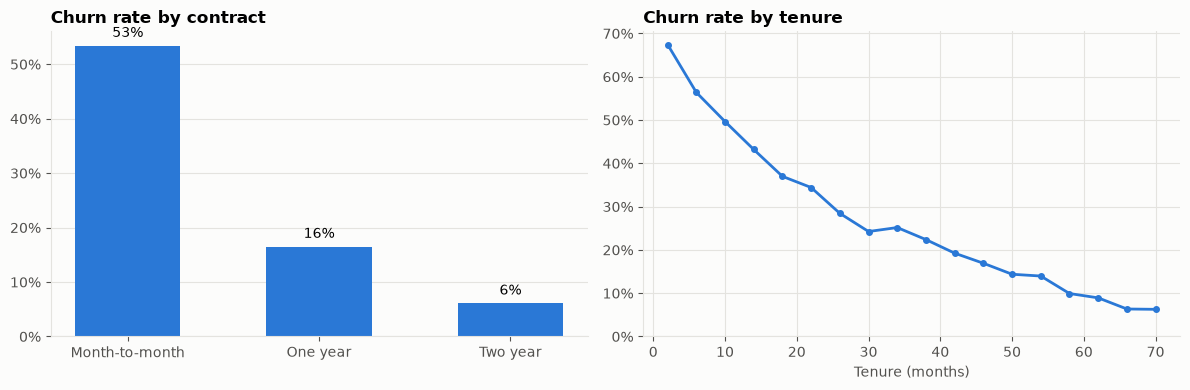

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Churn rate by contract
rate = y_all.groupby(df["contract"]).mean().reindex(["Month-to-month", "One year", "Two year"])
bars = ax1.bar(rate.index, rate.values, color=BLUE, width=0.55)
ax1.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=4)
ax1.set_title("Churn rate by contract")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.grid(axis="x", visible=False)

# Churn rate by tenure (4-month bins)
bins = np.arange(0, 76, 4)
tenure_rate = y_all.groupby(pd.cut(df["tenure"], bins, right=False), observed=True).mean()
ax2.plot([b.left + 2 for b in tenure_rate.index], tenure_rate.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax2.set_title("Churn rate by tenure")
ax2.set_xlabel("Tenure (months)")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_ylim(0, None)
plt.tight_layout()

## Features and target

8 features kept by `src/feature_selection.py`: dropping the other 11 did not lower CV ROC AUC or F1.

In [4]:
num_cols = ["senior_citizen", "monthly_charges"]
log_cols = ["tenure"]  # log-transformed below
cat_cols = ["contract", "tech_support", "internet_service", "payment_method", "online_security"]

X = df[num_cols + log_cols + cat_cols]
y = y_all

## Preprocessing pipelines

In [5]:
# Numbers: fill missing with mean, then scale
num_pipelines = Pipeline([
    ("imp", SimpleImputer(strategy="mean")),
    ("sc", StandardScaler())
])

# Tenure: churn risk drops fast in early months, so use log1p
log_pipelines = Pipeline([
    ("imp", SimpleImputer(strategy="mean")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("sc", StandardScaler())
])

# Categories: fill missing with most frequent, then one-hot encode
cat_pipelines = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

prep = ColumnTransformer([
    ("num", num_pipelines, num_cols),
    ("tenure", log_pipelines, log_cols),
    ("cat", cat_pipelines, cat_cols)
], verbose_feature_names_out=False)

## Train / test split (80/20, keep churn ratio)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Candidate models and hyperparameter grids

In [7]:
models = {
    "LR": LogisticRegression(max_iter=1000),
    "RF": RandomForestClassifier(random_state=42),
    "HGB": HistGradientBoostingClassifier(random_state=42),
}

# Let CV decide: log tenure or raw tenure (trees don't need this)
tenure_options = {"prep__tenure__log": [FunctionTransformer(np.log1p, feature_names_out="one-to-one"), "passthrough"]}

param_grids = {
    "LR": {
        **tenure_options,
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": ["balanced", None],
    },
    "RF": {
        "model__n_estimators": [300],
        "model__max_depth": [5, 10, 20],
        "model__min_samples_leaf": [1, 5, 20],
        "model__class_weight": ["balanced", None],
    },
    "HGB": {
        "model__learning_rate": [0.03, 0.1],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__l2_regularization": [0.0, 1.0],
        "model__class_weight": ["balanced", None],
    },
}

## Tune each model, then compare (5-fold CV, ROC AUC)

ROC AUC doesn't depend on the threshold, which is tuned in the next step.

In [8]:
searches = {}
for name, model in models.items():
    search = GridSearchCV(
        Pipeline([("prep", prep), ("model", model)]),
        param_grid=param_grids[name],
        cv=5,
        scoring="roc_auc",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name} CV ROC AUC: {search.best_score_:.4f}  {search.best_params_}")

best_name = max(searches, key=lambda n: searches[n].best_score_)
print(f"Best model: {best_name}")

LR CV ROC AUC: 0.8536  {'model__C': 100, 'model__class_weight': None, 'prep__tenure__log': FunctionTransformer(feature_names_out='one-to-one', func=<ufunc 'log1p'>)}


RF CV ROC AUC: 0.8485  {'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 20, 'model__n_estimators': 300}


HGB CV ROC AUC: 0.8493  {'model__class_weight': None, 'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_leaf_nodes': 7}
Best model: LR


## Pick the decision threshold (instead of 0.5)

Maximises CV F1 on train data. Change `scoring` to favour recall or precision.

In [9]:
best_model = TunedThresholdClassifierCV(
    searches[best_name].best_estimator_,
    scoring="f1",
    cv=5,
    n_jobs=-1,
)
best_model.fit(X_train, y_train)
print(f"Threshold: {best_model.best_threshold_:.3f}  (CV F1: {best_model.best_score_:.4f})")

# Save model (includes preprocessing and threshold)
model_path = ROOT / "models" / "model.joblib"
model_path.parent.mkdir(exist_ok=True)
joblib.dump(best_model, model_path)

Threshold: 0.359  (CV F1: 0.6710)


['C:\\Users\\Admin\\code\\project\\Customer-Churn-Prediction\\models\\model.joblib']

## Final test (use the test set only here)

In [10]:
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = best_model.predict(X_test)

print(f"Test ROC AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test ROC AUC: 0.8542
Test accuracy: 0.7960
[[1192  244]
 [ 164  400]]
              precision    recall  f1-score   support

           0       0.88      0.83      0.85      1436
           1       0.62      0.71      0.66       564

    accuracy                           0.80      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.81      0.80      0.80      2000



## Precision and recall by threshold

A lower threshold catches more churners but raises more false alarms.

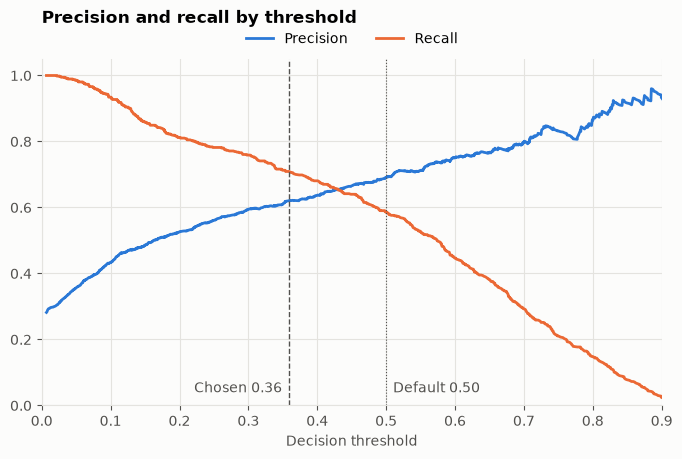

In [11]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
t = best_model.best_threshold_

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, precision[:-1], color=BLUE, linewidth=2, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, linewidth=2, label="Recall")
ax.axvline(t, color=TEXT_2, linewidth=1, linestyle="--")
ax.text(t - 0.01, 0.04, f"Chosen {t:.2f}", color=TEXT_2, ha="right")
ax.axvline(0.5, color=TEXT_2, linewidth=0.8, linestyle=":")
ax.text(0.51, 0.04, "Default 0.50", color=TEXT_2)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.set_title("Precision and recall by threshold", pad=26)
ax.set_xlabel("Decision threshold")
ax.set_xlim(0, 0.9)  # few customers score above 0.9, so the curve gets noisy there
ax.set_ylim(0, 1.05);

## Feature importance (for reporting only, not for choosing features)

How much test ROC AUC drops when each feature is shuffled.

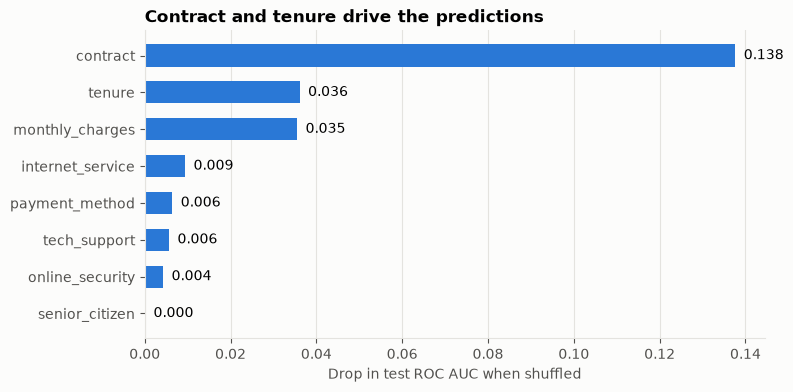

In [12]:
result = permutation_importance(
    best_model,
    X_test, y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(max(v, 0) + 0.002, i, f"{v:.3f}", va="center")
ax.set_title("Contract and tenure drive the predictions")
ax.set_xlabel("Drop in test ROC AUC when shuffled")
ax.grid(axis="y", visible=False);